# 02 - Análisis exploratorio de datos (EDA)

## Objetivo

Realizar un análisis exploratorio del dataset Chronic Kidney Disease para comprender su estructura, caracterizar las variables y explorar posibles relaciones entre ellas.

Se analizarán las distribuciones de las variables numéricas y categóricas, la presencia de datos faltantes y posibles valores atípicos. También se explorarán las relaciones entre las variables clínicas y la variable objetivo (`class`), que identifica la presencia o ausencia de enfermedad renal crónica.

El análisis permitirá identificar patrones y características relevantes del dataset, así como aspectos que deberán considerarse en las siguientes etapas del trabajo.

In [106]:
# 1. Importar bibliotecas
import sys
from pathlib import Path
import importlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Encontrar automáticamente la raíz del proyecto
PROJECT_ROOT = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "helpers").is_dir():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró la carpeta 'helpers'. "
        "Verificá desde qué directorio se está ejecutando la notebook."
    )


# 3. Agregar la raíz del proyecto a las rutas de búsqueda
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# 4. Definir las rutas de los archivos
PROCESSED_PATH = (PROJECT_ROOT/ "data"/ "processed"/ "chronic_kidney_disease_fixed.arff"
)

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Dataset: {PROCESSED_PATH}")

# 5. Importar y recargar el helper de EDA
import helpers.eda_utils
importlib.reload(helpers.eda_utils)

from helpers.eda_utils import (
    load_arff_dataset,
    decode_categorical_values,
    replace_missing_values,
    set_variable_types,
    classify_skewness,
    classify_kurtosis
)

import helpers.funciones_visualizacion_EDA
importlib.reload(helpers.funciones_visualizacion_EDA)

from helpers.funciones_visualizacion_EDA import (
    plot_distribution,
    plot_boxplot
)

Raíz del proyecto: c:\Users\Meli\OneDrive\Documentos\Maestría IA\Especialización IA\CEIA_AndD\Chronic-Kidney-Disease-EDA-ActividadIndividual2-Piacentino
Dataset: c:\Users\Meli\OneDrive\Documentos\Maestría IA\Especialización IA\CEIA_AndD\Chronic-Kidney-Disease-EDA-ActividadIndividual2-Piacentino\data\processed\chronic_kidney_disease_fixed.arff


## 1. Inspección general del dataset

Se carga el dataset acondicionado en `01_acondicionamiento_dataset.ipynb` para realizar una primera inspección de su estructura y contenido.

Se revisan sus dimensiones, los nombres de las variables, los primeros registros y los tipos de datos asignados por Pandas.

### 1.1. Carga del dataset

Para comenzar el análisis exploratorio, se cargó el archivo ARFF previamente acondicionado y se convirtió su contenido a un DataFrame de pandas mediante la función `load_arff_dataset()`, definida en el módulo `helpers/eda_utils.py`.

Esta función realiza las siguientes operaciones:

1. **Lectura del archivo ARFF:** lee el contenido del archivo e identifica el comienzo de la sección de datos.
2. **Normalización del formato:** elimina espacios sobrantes al principio y al final de los campos para evitar inconsistencias durante la interpretación de los valores.
3. **Conversión a DataFrame:** utiliza `scipy.io.arff.loadarff()` para interpretar el archivo ARFF y obtener los registros, que posteriormente se convierten en un DataFrame de pandas.

In [107]:
# 6. Cargar el dataset procesado
cdk_df = load_arff_dataset(PROCESSED_PATH)

print("Dataset cargado correctamente.")
print(f"Dimensiones: {cdk_df.shape[0]} registros y {cdk_df.shape[1]} variables.")
cdk_df.head()

Dataset cargado correctamente.
Dimensiones: 400 registros y 25 variables.


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,b'1.020',b'1',b'0',b'?',b'normal',b'notpresent',b'notpresent',121.0,...,44.0,7800.0,5.2,b'yes',b'yes',b'no',b'good',b'no',b'no',b'ckd'
1,7.0,50.0,b'1.020',b'4',b'0',b'?',b'normal',b'notpresent',b'notpresent',NaN,...,38.0,6000.0,NaN,b'no',b'no',b'no',b'good',b'no',b'no',b'ckd'
2,62.0,80.0,b'1.010',b'2',b'3',b'normal',b'normal',b'notpresent',b'notpresent',423.0,...,31.0,7500.0,NaN,b'no',b'yes',b'no',b'poor',b'no',b'yes',b'ckd'
3,48.0,70.0,b'1.005',b'4',b'0',b'normal',b'abnormal',b'present',b'notpresent',117.0,...,32.0,6700.0,3.9,b'yes',b'no',b'no',b'poor',b'yes',b'yes',b'ckd'
4,51.0,80.0,b'1.010',b'2',b'0',b'normal',b'normal',b'notpresent',b'notpresent',106.0,...,35.0,7300.0,4.6,b'no',b'no',b'no',b'good',b'no',b'no',b'ckd'


Al visualizar los primeros registros del DataFrame mediante df.head(), se observa que los valores faltantes se representan de manera diferente según el tipo de variable: en las variables categóricas aparecen como `?`, mientras que en las numéricas se muestran como `NaN`.

### 1.2. Decodificación de variables categóricas

Al cargar el archivo ARFF, los valores de las variables categóricas pueden quedar almacenados como secuencias de bytes (`bytes`) en lugar de cadenas de texto (`str`).

Para facilitar su manipulación y análisis mediante pandas, se implementó la función `decode_categorical_values()`, que identifica las columnas de tipo `object` y convierte los valores almacenados como bytes a cadenas de texto mediante su decodificación con UTF-8.

Esta operación modifica la representación de los valores en memoria, sin alterar el contenido de las categorías.

In [108]:
cdk_df = decode_categorical_values(cdk_df)

print("Variables categóricas decodificadas correctamente.")

Variables categóricas decodificadas correctamente.


### 1.3. Conversión de valores faltantes

En el archivo ARFF original, se representan mediante el símbolo `?`. Para facilitar su identificación y posterior análisis con pandas, se implementó la función `replace_missing_values()`, que reemplaza esta representación por `NaN`.

In [109]:
cdk_df = replace_missing_values(cdk_df)

print("Valores faltantes convertidos correctamente.")
cdk_df.head()

Valores faltantes convertidos correctamente.


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1,0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4,0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2,3,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4,0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2,0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


## 2. Descripción y clasificación de las variables

El dataset contiene 25 variables: 24 atributos que describen características clínicas y resultados de laboratorio de los pacientes, y una variable objetivo (`class`) que indica la presencia o ausencia de enfermedad renal crónica.

A partir de la documentación proporcionada por UCI, se identificaron las variables y se clasificaron según su naturaleza. Para las variables numéricas, se distingue entre discretas (`Integer`) y continuas (`Continuous`). Las variables categóricas se clasifican en ordinales y nominales, según la existencia o no de un orden entre sus categorías.

| Variable | Tipo de variable | Descripción |
|---|---|---|
| `age` | Numérica discreta (Integer) | Edad del paciente (años). |
| `bp` | Numérica discreta (Integer) | Presión arterial (mmHg). |
| `sg` | Categórica ordinal | Gravedad específica. |
| `al` | Categórica ordinal | Nivel de albúmina. |
| `su` | Categórica ordinal | Nivel de azúcar. |
| `rbc` | Categórica nominal (Binary) | Características de los glóbulos rojos: normales o anormales. |
| `pc` | Categórica nominal (Binary) | Características de las células de pus: normales o anormales. |
| `pcc` | Categórica nominal (Binary) | Presencia o ausencia de agrupaciones de células de pus. |
| `ba` | Categórica nominal (Binary) | Presencia o ausencia de bacterias. |
| `bgr` | Numérica discreta (Integer) | Glucemia aleatoria (mg/dL). |
| `bu` | Numérica discreta (Integer) | Urea en sangre (mg/dL). |
| `sc` | Numérica continua (Continuous) | Creatinina sérica (mg/dL). |
| `sod` | Numérica discreta (Integer) | Concentración de sodio (mEq/L). |
| `pot` | Numérica continua (Continuous) | Concentración de potasio (mEq/L). |
| `hemo` | Numérica continua (Continuous) | Concentración de hemoglobina (g/dL). |
| `pcv` | Numérica discreta (Integer) | Volumen celular empaquetado. |
| `wbcc` | Numérica discreta (Integer) | Recuento de glóbulos blancos (células/mm³). |
| `rbcc` | Numérica continua (Continuous) | Recuento de glóbulos rojos (millones/mm³). |
| `htn` | Categórica nominal (Binary) | Presencia o ausencia de hipertensión. |
| `dm` | Categórica nominal (Binary) | Presencia o ausencia de diabetes mellitus. |
| `cad` | Categórica nominal (Binary) | Presencia o ausencia de enfermedad arterial coronaria. |
| `appet` | Categórica nominal (Binary) | Apetito: bueno o malo. |
| `pe` | Categórica nominal (Binary) | Presencia o ausencia de edema periférico. |
| `ane` | Categórica nominal (Binary) | Presencia o ausencia de anemia. |
| `class` | Categórica nominal (objetivo) | Clasificación del paciente: enfermedad renal crónica (`ckd`) o ausencia de enfermedad renal crónica (`notckd`). |

En total, se identificaron:
- **7 variables numéricas discretas.**
- **4 variables numéricas continuas.**
- **3 variables categóricas ordinales:** `sg`, `al` y `su`.
- **11 variables categóricas nominales**, incluyendo la variable objetivo `class`.


**Criterio de clasificación de las variables ordinales:**

Aunque UCI clasifica originalmente las variables `sg`, `al` y `su` como categóricas nominales, en este análisis se decidió tratarlas como categóricas ordinales debido a la naturaleza de sus valores:

- `sg` (Specific Gravity): presenta cinco categorías numéricas ordenadas de menor a mayor [1.005, 1.010, 1.015, 1.020 y 1.025].
- `al` (Albumin): presenta seis categorías ordenadas de 0 a 5.
- `su` (Sugar): presenta seis categorías ordenadas de 0 a 5.

Por este motivo, se considera que estas variables presentan un orden inherente entre sus categorías, aunque no se asume que las diferencias entre categorías consecutivas sean equivalentes.

In [110]:
# Se verifica el dtype que asigno Padas:
cdk_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    object 
 3   al      354 non-null    object 
 4   su      351 non-null    object 
 5   rbc     248 non-null    object 
 6   pc      335 non-null    object 
 7   pcc     396 non-null    object 
 8   ba      396 non-null    object 
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    object 
 19  dm      398 non-null    object 
 20  cad     398 non-null    object 
 21  appet   399 non-null    object 
 22  pe

Se identifican y agrupan las variables del dataset según su naturaleza

In [111]:
# Variables categóricas ordinales y sus categorías ordenadas
ordinal_categories = {
    "sg": ["1.005", "1.010", "1.015", "1.020", "1.025"],
    "al": ["0", "1", "2", "3", "4", "5"],
    "su": ["0", "1", "2", "3", "4", "5"]
    }

# Variables categóricas nominales serán el resto de las variables
nominal_categories = cdk_df.select_dtypes(include=["object"]).columns.difference(ordinal_categories.keys())

# Variables numéricas discretas (Integer)
discrete_columns = [
    "age", "bp", "bgr", "bu", "sod", "pcv", "wbcc"
]

# Variables numéricas continuas (Continuous)
continuous_columns = [
    "sc", "pot", "hemo", "rbcc"
]


Posteriormente, se utilizó la función `set_variable_types()`, definida en `helpers/eda_utils.py`, para ajustar los tipos de datos en pandas:

- Las variables numéricas se convirtieron a `float64`.
- Las variables categóricas nominales se convirtieron a `category`.
- Las variables categóricas ordinales se convirtieron a `category`, estableciendo el orden de sus categorías.

Además, se verificó que los valores de las variables ordinales pertenezcan a las categorías definidas.

In [112]:
numeric_columns = discrete_columns + continuous_columns # Todas las variables numéricas

cdk_df = set_variable_types(cdk_df, numeric_columns, ordinal_categories, nominal_categories)
cdk_df.dtypes

age       float64
bp        float64
sg       category
al       category
su       category
rbc      category
pc       category
pcc      category
ba       category
bgr       float64
bu        float64
sc        float64
sod       float64
pot       float64
hemo      float64
pcv       float64
wbcc      float64
rbcc      float64
htn      category
dm       category
cad      category
appet    category
pe       category
ane      category
class    category
dtype: object

In [113]:
print("Categorías de sg:", cdk_df["sg"].dropna().unique())
print("Categorías de al:", cdk_df["al"].dropna().unique())
print("Categorías de su:", cdk_df["su"].dropna().unique())

Categorías de sg: ['1.020', '1.010', '1.005', '1.015', '1.025']
Categories (5, object): ['1.005' < '1.010' < '1.015' < '1.020' < '1.025']
Categorías de al: ['1', '4', '2', '3', '0', '5']
Categories (6, object): ['0' < '1' < '2' < '3' < '4' < '5']
Categorías de su: ['0', '3', '4', '1', '2', '5']
Categories (6, object): ['0' < '1' < '2' < '3' < '4' < '5']


## 2. Estadística descriptiva

### 2.1. Exploración de VARIABLES NUMÉRICAS

#### 2.1.1. Variables Continuas

In [114]:
# Estadística descriptiva de variables continuas
numeric_continuous_description = cdk_df[continuous_columns].describe().T
# Renombrar la mediana
numeric_continuous_description = numeric_continuous_description.rename(columns={"50%": "median"})
# Calcular rango intercuartílico
numeric_continuous_description["IQR"] = (numeric_continuous_description["75%"] - numeric_continuous_description["25%"])
# Calcular cantidad de valores faltantes
numeric_continuous_description["missing"] = (cdk_df[continuous_columns].isna().sum())
# Redondeamos los valores a 2 decimales
numeric_continuous_description.round(2)

,count,mean,std,min,25%,median,75%,max,IQR,missing
sc,383.0,3.07,5.74,0.4,0.9,1.30,2.8,76.0,1.9,17
pot,312.0,4.63,3.19,2.5,3.8,4.40,4.9,47.0,1.1,88
hemo,348.0,12.53,2.91,3.1,10.3,12.65,15.0,17.8,4.7,52
rbcc,269.0,4.71,1.03,2.1,3.9,4.80,5.4,8.0,1.5,131


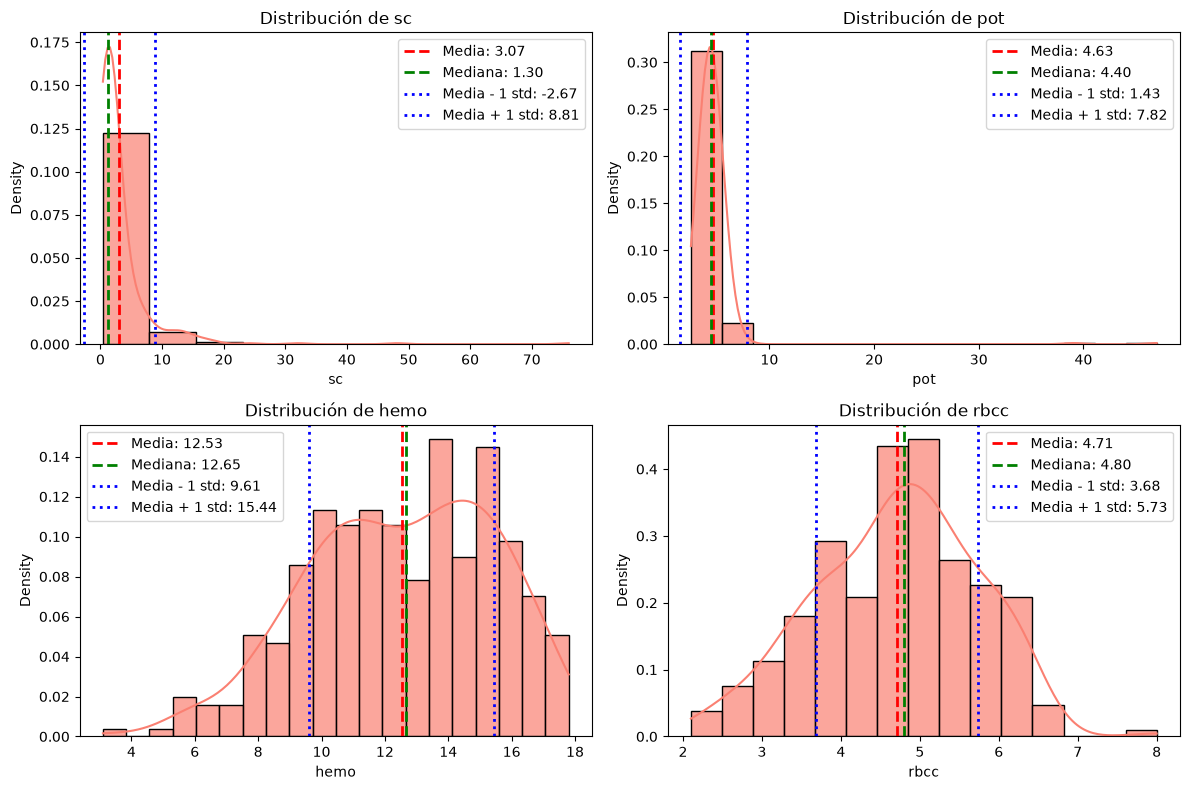

In [115]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_distribution(df=cdk_df, column="sc", bins=10, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[0, 0])

plot_distribution(df=cdk_df, column="pot", bins=15, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[0, 1])

plot_distribution(df=cdk_df, column="hemo", bins=20, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[1, 0])

plot_distribution(df=cdk_df, column="rbcc", bins=15, kde=True, show_mode=False, show_mean=True, show_median=True, type_stat= "density", ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [123]:
continuous_distribution = pd.DataFrame(index=continuous_columns)
continuous_distribution["skewness"] = cdk_df[continuous_columns].skew()
continuous_distribution["symmetry"] = continuous_distribution["skewness"].apply(classify_skewness)
continuous_distribution["kurtosis"] = cdk_df[continuous_columns].kurt()
continuous_distribution["kurtosis_type"] = continuous_distribution["kurtosis"].apply(lambda x: classify_kurtosis(x, tolerance=0.3))
continuous_distribution.round(3)

,skewness,symmetry,kurtosis,kurtosis_type
sc,7.510,Asimetría alta,79.304,Leptocúrtica
pot,11.583,Asimetría alta,142.506,Leptocúrtica
hemo,-0.335,Aproximadamente simétrica,-0.471,Platicúrtica
rbcc,-0.183,Aproximadamente simétrica,-0.270,Aproximadamente Mesocúrtica


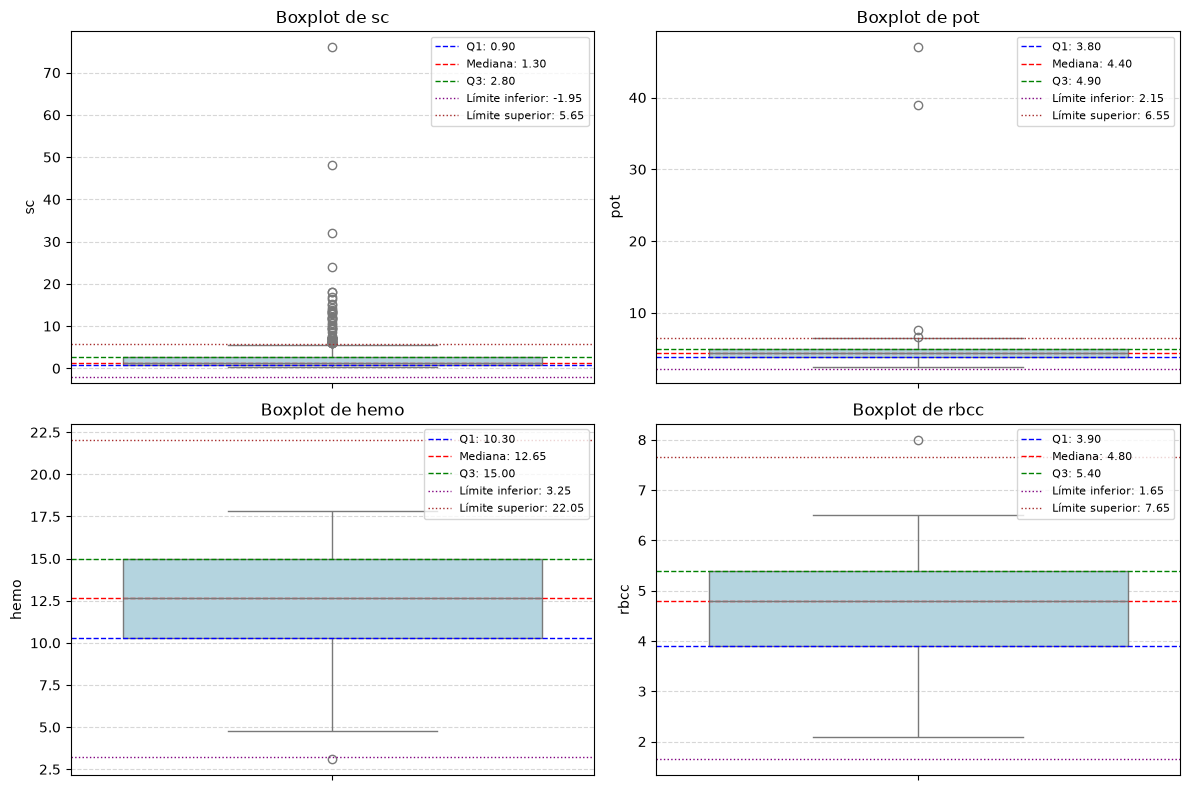

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_boxplot(df=cdk_df, column="sc", showfliers=True, show_details=True, ax=axes[0, 0])
plot_boxplot(df=cdk_df, column="pot", showfliers=True, show_details=True, ax=axes[0, 1])
plot_boxplot(df=cdk_df, column="hemo", showfliers=True, show_details=True, ax=axes[1, 0])
plot_boxplot(df=cdk_df, column="rbcc", showfliers=True, show_details=True, ax=axes[1, 1])

plt.tight_layout()
plt.show()

#### 2.1.2. Variables Discretas

In [118]:
numeric_discrete_description = cdk_df[discrete_columns].describe().T

# Renombrar la mediana
numeric_discrete_description = numeric_discrete_description.rename(
    columns={"50%": "median"}
)

# Calcular todas las modas
numeric_discrete_description["mode"] = (
    cdk_df[discrete_columns]
    .mode()
    .apply(lambda col: col.dropna().tolist())
)

# Calcular rango intercuartílico
numeric_discrete_description["IQR"] = (
    numeric_discrete_description["75%"] -
    numeric_discrete_description["25%"]
)

# Calcular cantidad de valores faltantes
numeric_discrete_description["missing"] = cdk_df[discrete_columns].isna().sum()

# Redondear los valores a 2 decimales
numeric_discrete_description.round(2)

,count,mean,std,min,25%,median,75%,max,mode,IQR,missing
age,391.0,51.48,17.17,2.0,42.0,55.0,64.5,90.0,[60.0],22.5,9
bp,388.0,76.47,13.68,50.0,70.0,80.0,80.0,180.0,[80.0],10.0,12
bgr,356.0,148.04,79.28,22.0,99.0,121.0,163.0,490.0,[99.0],64.0,44
bu,381.0,57.43,50.50,1.5,27.0,42.0,66.0,391.0,[46.0],39.0,19
sod,313.0,137.53,10.41,4.5,135.0,138.0,142.0,163.0,[135.0],7.0,87
pcv,329.0,38.88,8.99,9.0,32.0,40.0,45.0,54.0,"[41.0, 52.0]",13.0,71
wbcc,294.0,8406.12,2944.47,2200.0,6500.0,8000.0,9800.0,26400.0,[9800.0],3300.0,106


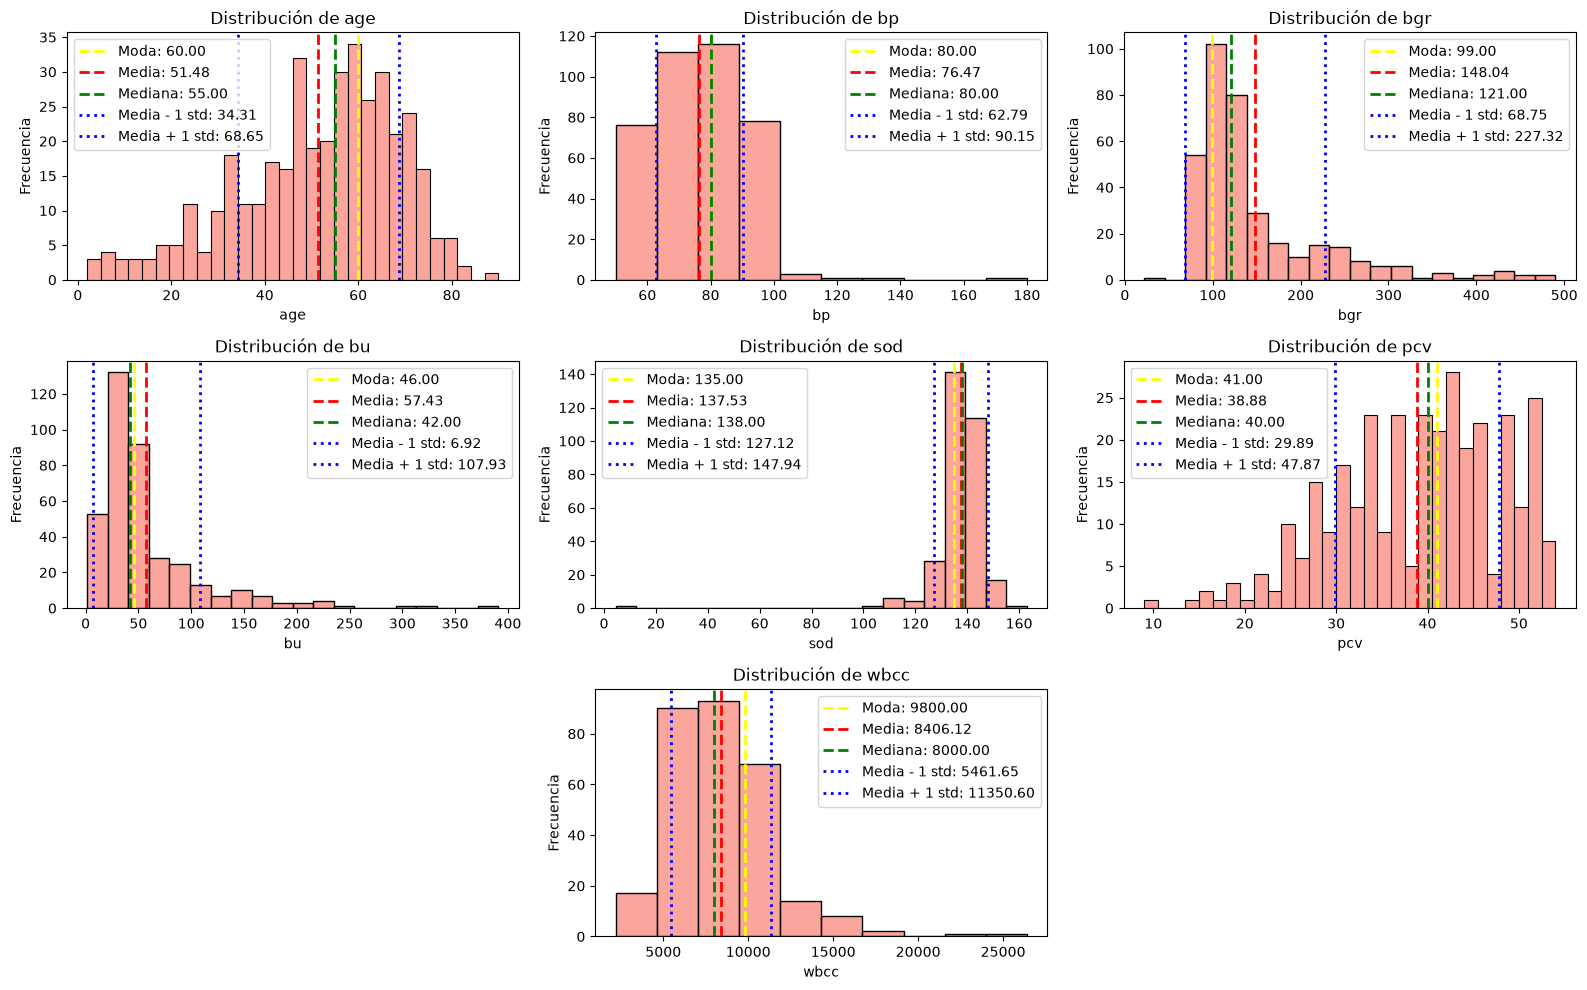

In [119]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10))

plot_distribution(df=cdk_df, column="age", bins=30, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 0])
plot_distribution(df=cdk_df, column="bp", bins=10, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 1])
plot_distribution(df=cdk_df, column="bgr", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[0, 2])
plot_distribution(df=cdk_df, column="bu", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 0])
plot_distribution(df=cdk_df, column="sod", bins=20, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 1])
plot_distribution(df=cdk_df, column="pcv", bins=30, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[1, 2])
plot_distribution(df=cdk_df, column="wbcc", bins=10, kde=False, show_mode=True, show_mean=True, show_median=True, type_stat="count", ax=axes[2, 1])

# Ocultar los espacios sin gráficos
axes[2, 0].set_visible(False)
axes[2, 2].set_visible(False)

plt.tight_layout()
plt.show()

In [126]:
discrete_distribution = pd.DataFrame(index=discrete_columns)
discrete_distribution["skewness"] = cdk_df[discrete_columns].skew()
discrete_distribution["symmetry"] = discrete_distribution["skewness"].apply(classify_skewness)
discrete_distribution["kurtosis"] = cdk_df[discrete_columns].kurt()
discrete_distribution["kurtosis_type"] = discrete_distribution["kurtosis"].apply(lambda x: classify_kurtosis(x, tolerance=0.1))
discrete_distribution.round(3)

,skewness,symmetry,kurtosis,kurtosis_type
age,-0.668,Asimetría moderada,0.058,Aproximadamente Mesocúrtica
bp,1.605,Asimetría alta,8.646,Leptocúrtica
bgr,2.011,Asimetría alta,4.226,Leptocúrtica
bu,2.634,Asimetría alta,9.345,Leptocúrtica
sod,-6.997,Asimetría alta,85.534,Leptocúrtica
pcv,-0.434,Aproximadamente simétrica,-0.321,Platicúrtica
wbcc,1.622,Asimetría alta,6.151,Leptocúrtica


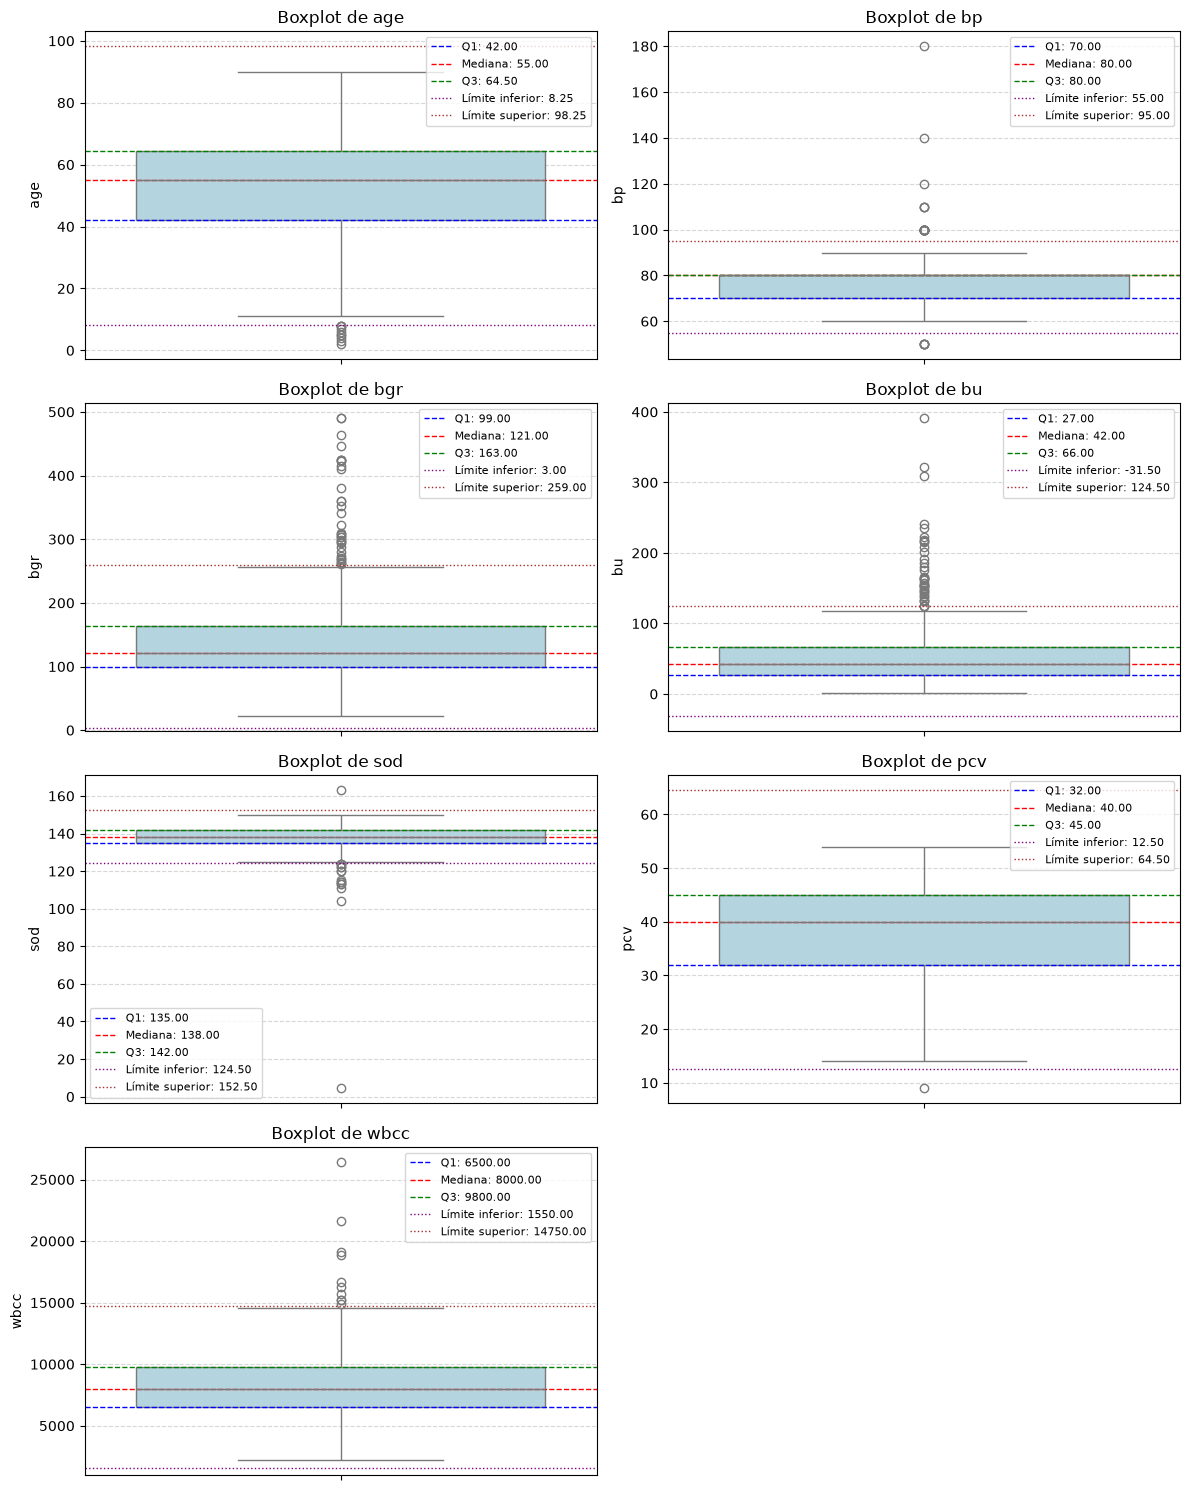

In [120]:
fig, axes = plt.subplots(4, 2, figsize=(12, 15))

plot_boxplot(df=cdk_df, column="age", showfliers=True, show_details=True, ax=axes[0, 0])

plot_boxplot(df=cdk_df, column="bp", showfliers=True, show_details=True, ax=axes[0, 1])

plot_boxplot(df=cdk_df, column="bgr", showfliers=True, show_details=True, ax=axes[1, 0])

plot_boxplot(df=cdk_df, column="bu", showfliers=True, show_details=True, ax=axes[1, 1])

plot_boxplot(df=cdk_df, column="sod", showfliers=True, show_details=True, ax=axes[2, 0])

plot_boxplot(df=cdk_df, column="pcv", showfliers=True, show_details=True, ax=axes[2, 1])

plot_boxplot(df=cdk_df, column="wbcc", showfliers=True, show_details=True, ax=axes[3, 0])

# Ocultar los espacios sin gráficos
axes[3, 1].set_visible(False)

plt.tight_layout()
plt.show()

,skewness,symmetry,kurtosis,kurtosis_type
age,-0.668,Asimetría moderada,0.058,Aproximadamente Mesocúrtica
bp,1.605,Asimetría alta,8.646,Leptocúrtica
bgr,2.011,Asimetría alta,4.226,Leptocúrtica
bu,2.634,Asimetría alta,9.345,Leptocúrtica
sod,-6.997,Asimetría alta,85.534,Leptocúrtica
pcv,-0.434,Aproximadamente simétrica,-0.321,Platicúrtica
wbcc,1.622,Asimetría alta,6.151,Leptocúrtica
